# News categories and subsequent Bitcoin returns

This approved descriptive study compares Bitcoin, crypto, politics and war/macro sentiment scores with subsequent 1, 4, 12 and 24-hour BTC returns. It uses only the original **192 observations from September 24 to October 31, 2026**, enriched with their matching category scores from Azure.

The **40 newer observations are excluded**. No category weights, trading thresholds, holding periods or strategies are selected here. Recorded HOLD labels are collection placeholders and are ignored.

Use the same frozen hourly Binance prices and timing as the previous research: measure returns from the next hourly open strictly after a score timestamp to the hourly open 1/4/12/24 hours later. Endpoints beyond the frozen market data remain missing. Correlations describe association, not trading profitability or causation.


In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
%matplotlib inline

candidates = [Path.cwd(),Path.cwd()/"notebooks/category_research"]
HERE = next(p for p in candidates if (p/"audit_results/azure_matching_previous_192.csv").exists())
PROJECT = HERE.parents[1]
OUT = HERE/"category_results"
OUT.mkdir(exist_ok=True)
INPUTS = [HERE/"audit_results/azure_matching_previous_192.csv",
          PROJECT/"notebooks/recent_data/btc_hourly_recent.csv",
          PROJECT/"notebooks/recent_data/signals_recent.csv",
          PROJECT/"notebooks/results_recent/recent_score_correlations.csv"]
EXPECTED = {'azure_matching_previous_192.csv': 'f5fc7adaf15528c7bac8bb2c5a76be729cf55930e299f00772dd8584ed83500e', 'btc_hourly_recent.csv': '8b362387fe685c09c2da4149547f867b5eb3a905452a88cbafad65a210b53551', 'signals_recent.csv': 'b3a15d9f7375e01f24b5f1b18db8109c80102db425b47264925cead502db2e17', 'recent_score_correlations.csv': 'f0d9643c855e19b2274fb5b48e1a10a8fefafc7d3a63753d212d340c8f4352f3'}
for p in INPUTS:
    assert hashlib.sha256(p.read_bytes()).hexdigest()==EXPECTED[p.name],p.name
signals = pd.read_csv(INPUTS[0])
old = pd.read_csv(INPUTS[2])
market = pd.read_csv(INPUTS[1])
signals["timestamp"] = pd.to_datetime(signals.timestamp,format="mixed",utc=True)
old["timestamp"] = pd.to_datetime(old.timestamp,format="mixed",utc=True)
market["open_time"] = pd.to_datetime(market.open_time,utc=True)
signals = signals.sort_values("timestamp").reset_index(drop=True)
old = old.sort_values("timestamp").reset_index(drop=True)
assert len(signals)==len(old)==192
assert signals.timestamp.dt.floor("ms").equals(old.timestamp.dt.floor("ms"))
assert signals.symbol.equals(old.symbol)
assert not signals.duplicated(["timestamp","symbol"]).any()
assert signals.timestamp.max().floor("ms")==old.timestamp.max()
assert signals.timestamp.min()>=pd.Timestamp("2026-09-01",tz="UTC")
CATEGORIES = {"bitcoin_score":"Bitcoin","crypto_score":"Crypto",
              "politics_score":"Politics","war_macro_score":"War / macro"}
HORIZONS = [1,4,12,24]
COLORS = ["#3663ad","#2d8976","#b5761d","#a35a88"]
assert np.isfinite(signals[list(CATEGORIES)].to_numpy()).all()
P = market.set_index("open_time").open
assert P.index.is_unique and P.index.is_monotonic_increasing
assert P.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
def save_chart(fig,name):
    fig.savefig(OUT/(name+".png"),dpi=150,bbox_inches="tight",facecolor="white")
    display(fig)
    plt.close(fig)
print("Observations:",len(signals),"|",signals.timestamp.min(),"to",signals.timestamp.max())
print("Last frozen hourly open:",P.index.max())


Observations: 192 | 2026-09-24 20:51:46.882448+00:00 to 2026-10-31 14:49:26.863784+00:00
Last frozen hourly open: 2026-10-31 14:00:00+00:00


## Timing and category-level correlations

Pearson measures a linear relationship. Spearman measures whether higher scores generally accompany higher returns by correlating their ranks. Positive values indicate higher scores accompanying higher subsequent BTC returns; negative values indicate the reverse. Values near zero indicate weak association in the measured form.

Each horizon has its own count of usable observations. Score timestamps are not rounded backward into an entry price. Returns span real elapsed hours and are not interpolated across unavailable endpoints. The observations and longer-horizon returns are dependent and overlapping, so ordinary independent-sample significance claims would be inappropriate. No significance tests are performed.


In [2]:
signals["entry_time"] = signals.timestamp.dt.floor("h")+pd.Timedelta(hours=1)
signals["entry_open"] = signals.entry_time.map(P)
assert signals.entry_time.gt(signals.timestamp).all()
rows = []
for h in HORIZONS:
    signals[f"exit_time_{h}h"] = signals.entry_time+pd.Timedelta(hours=h)
    signals[f"exit_open_{h}h"] = signals[f"exit_time_{h}h"].map(P)
    signals[f"forward_return_{h}h"] = signals[f"exit_open_{h}h"]/signals.entry_open-1
    for column,label in CATEGORIES.items():
        z = signals[[column,f"forward_return_{h}h"]].dropna()
        rows.append({"category":label,"score_column":column,"horizon_hours":h,
                     "observations":len(z),"pearson":z.iloc[:,0].corr(z.iloc[:,1]),
                     "spearman":z.iloc[:,0].rank().corr(z.iloc[:,1].rank())})
correlations = pd.DataFrame(rows)
assert len(correlations)==16
assert correlations.groupby("horizon_hours").observations.first().to_dict()=={1:191,4:190,12:188,24:185}
# Reproduce the published P/news/TA descriptive correlations on the same inputs.
prior = pd.read_csv(INPUTS[3])
for h in HORIZONS:
    for column,label in [("p_score","P-score"),("news_score","News"),("ta_score","Technical")]:
        z = signals[[column,f"forward_return_{h}h"]].dropna()
        ref = prior.loc[prior.horizon_hours.eq(h)&prior.score.eq(label)].iloc[0]
        assert len(z)==int(ref.observations)
        assert np.isclose(z.iloc[:,0].corr(z.iloc[:,1]),ref.pearson,atol=1e-12,rtol=0)
        assert np.isclose(z.iloc[:,0].rank().corr(z.iloc[:,1].rank()),ref.spearman,atol=1e-12,rtol=0)
# Independent endpoint lookup and Pearson calculation for every category/horizon.
for row in correlations.itertuples():
    pairs=[]
    for obs in signals.itertuples():
        entry=obs.timestamp.floor("h")+pd.Timedelta(hours=1)
        end=entry+pd.Timedelta(hours=row.horizon_hours)
        if entry in P.index and end in P.index:
            pairs.append((getattr(obs,row.score_column),float(P.loc[end])/float(P.loc[entry])-1))
    arr=np.array(pairs,dtype=float)
    assert len(arr)==row.observations
    assert np.isclose(np.corrcoef(arr[:,0],arr[:,1])[0,1],row.pearson,atol=1e-12,rtol=0)
display(correlations[["category","horizon_hours","observations","pearson","spearman"]].round(4))
correlations.to_csv(OUT/"category_forward_correlations.csv",index=False)
signals.to_csv(OUT/"original_192_categories_with_forward_returns.csv",index=False)


,category,horizon_hours,observations,pearson,spearman
0,Bitcoin,1,191,-0.0491,-0.0827
1,Crypto,1,191,-0.0586,-0.0365
2,Politics,1,191,0.0721,0.0537
3,War / macro,1,191,0.0107,-0.0045
4,Bitcoin,4,190,-0.0090,0.0004
5,Crypto,4,190,-0.0683,-0.0657
6,Politics,4,190,0.0489,0.0647
7,War / macro,4,190,-0.0050,0.0087
8,Bitcoin,12,188,0.0484,0.0921
9,Crypto,12,188,0.0072,0.0034


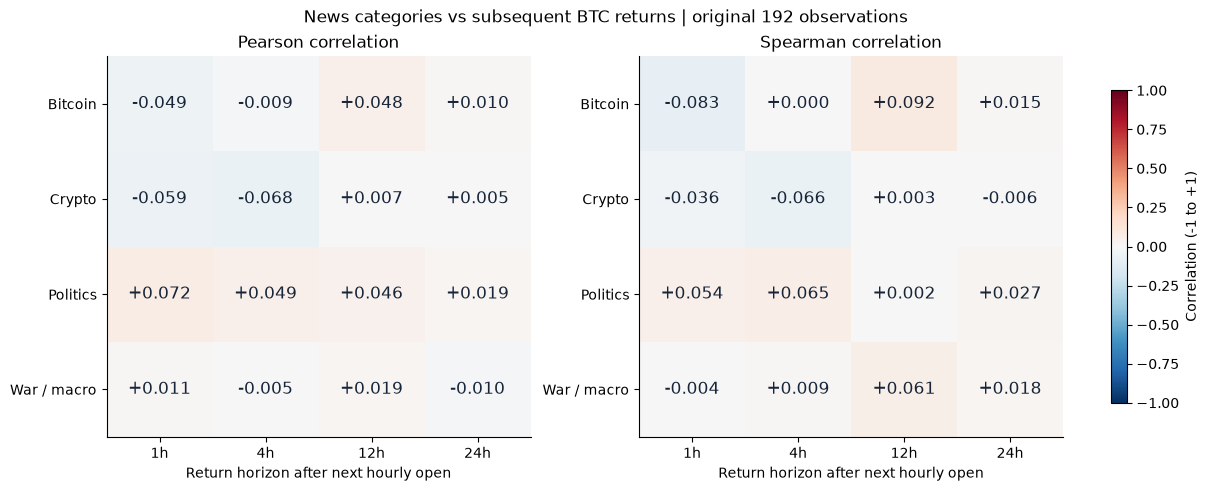

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout="constrained")
for ax,method in zip(axes,["pearson","spearman"]):
    matrix=correlations.pivot(index="category",columns="horizon_hours",values=method).reindex(list(CATEGORIES.values()))
    im=ax.imshow(matrix.to_numpy(),cmap="RdBu_r",vmin=-1,vmax=1,aspect="auto")
    ax.set_xticks(range(4),[f"{h}h" for h in HORIZONS])
    ax.set_yticks(range(4),matrix.index)
    ax.set_title(method.title()+" correlation")
    ax.set_xlabel("Return horizon after next hourly open")
    for i in range(4):
        for j in range(4):
            ax.text(j,i,f"{matrix.iloc[i,j]:+.3f}",ha="center",va="center",color="#172538",fontsize=12)
fig.colorbar(im,ax=axes,label="Correlation (-1 to +1)",shrink=.82)
fig.suptitle("News categories vs subsequent BTC returns | original 192 observations")
save_chart(fig,"category_correlation_comparison")


## Scatter plots for each category

Each point is a recorded score and a subsequent market return. Repeated score values, noisy relationships and extreme returns remain visible. These are gross price returns, without fees, slippage, trade selection or portfolio accounting.


### Bitcoin

,horizon_hours,observations,pearson,spearman
0,1,191,-0.0491,-0.0827
4,4,190,-0.0090,0.0004
8,12,188,0.0484,0.0921
12,24,185,0.0099,0.0152


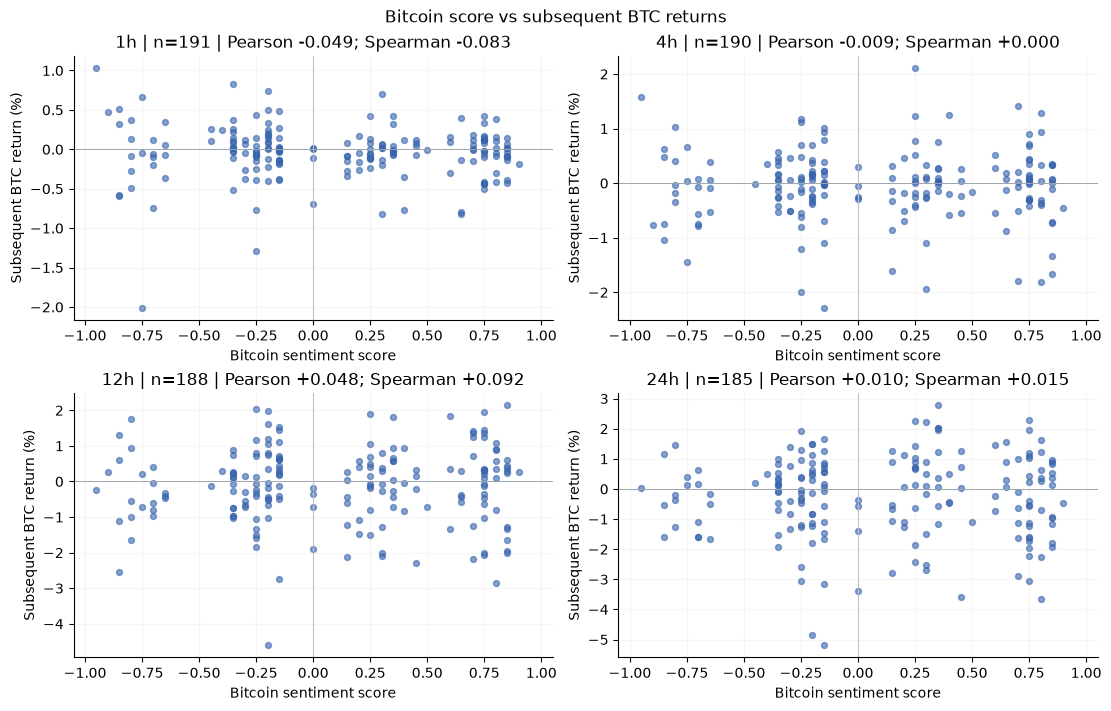

### Crypto

,horizon_hours,observations,pearson,spearman
1,1,191,-0.0586,-0.0365
5,4,190,-0.0683,-0.0657
9,12,188,0.0072,0.0034
13,24,185,0.0048,-0.0058


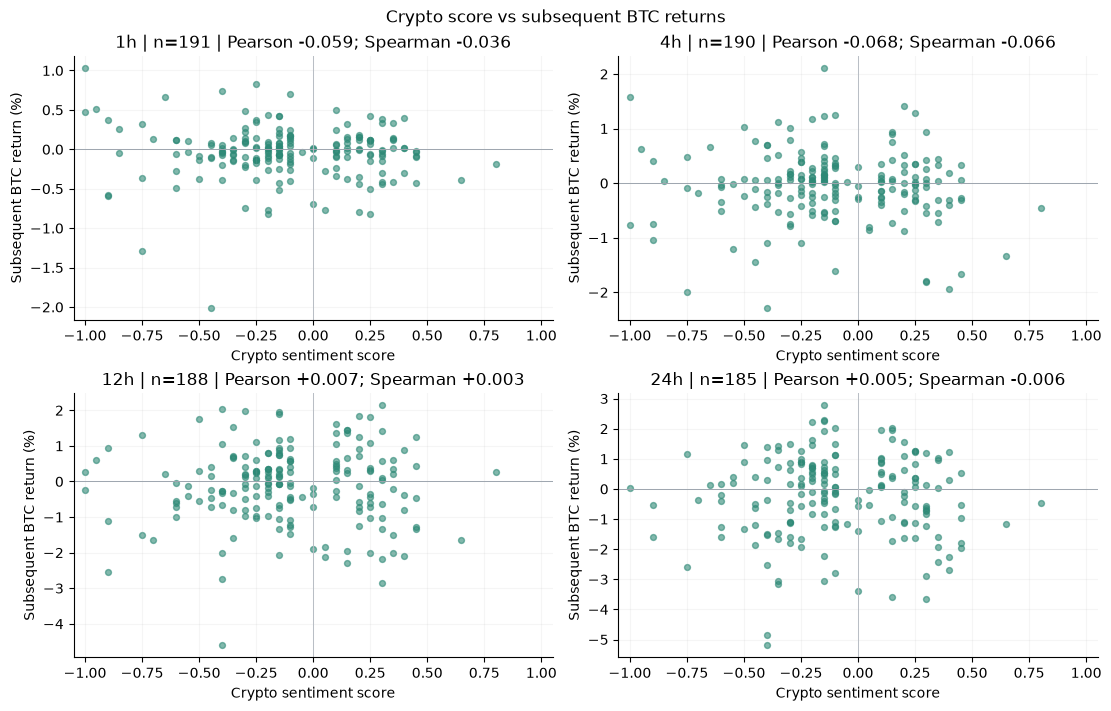

### Politics

,horizon_hours,observations,pearson,spearman
2,1,191,0.0721,0.0537
6,4,190,0.0489,0.0647
10,12,188,0.0464,0.0017
14,24,185,0.0193,0.0266


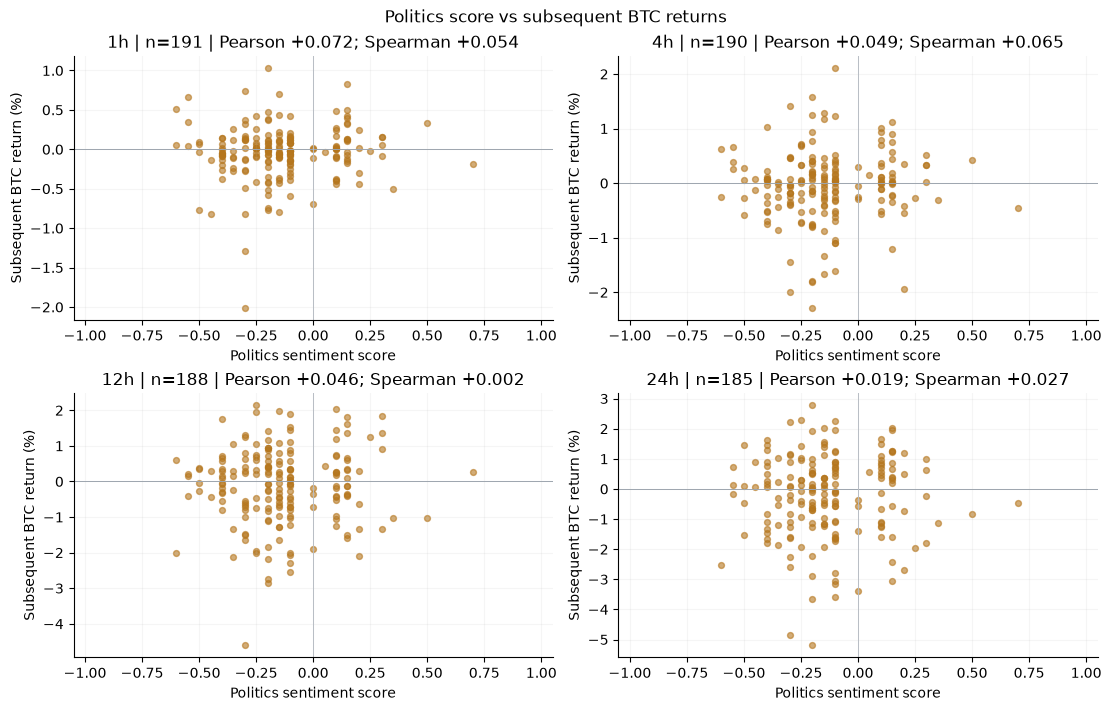

### War / macro

,horizon_hours,observations,pearson,spearman
3,1,191,0.0107,-0.0045
7,4,190,-0.0050,0.0087
11,12,188,0.0190,0.0607
15,24,185,-0.0096,0.0181


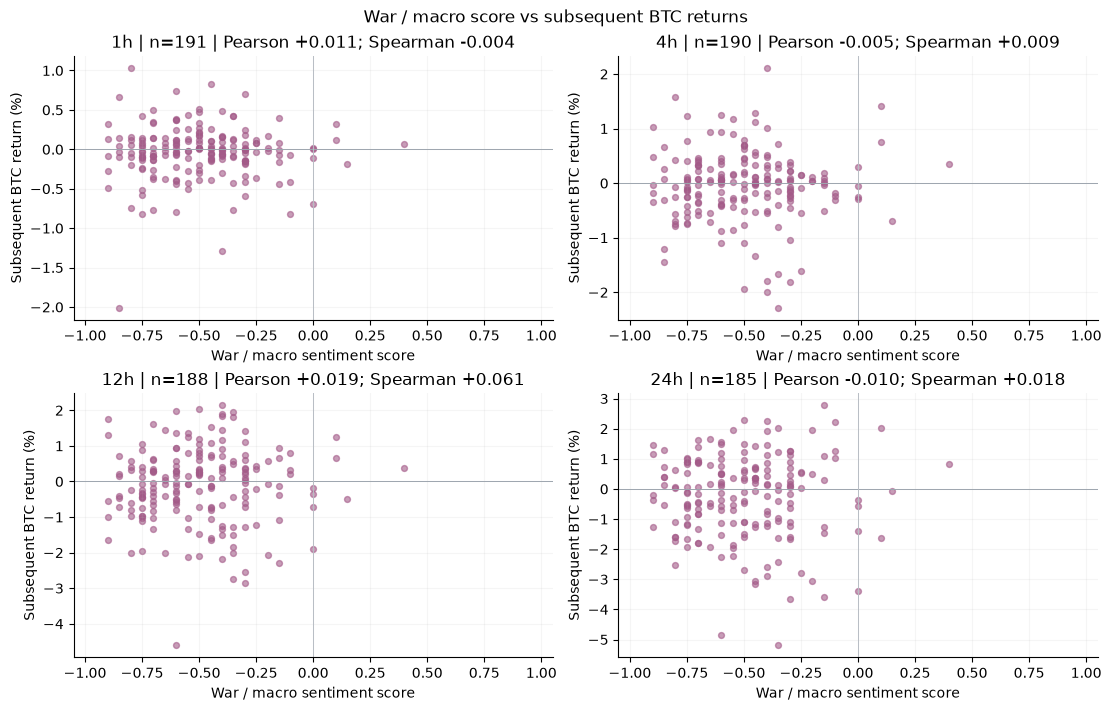

In [4]:
for (column,label),color in zip(CATEGORIES.items(),COLORS):
    display(Markdown("### "+label))
    display(correlations.loc[correlations.score_column.eq(column),
            ["horizon_hours","observations","pearson","spearman"]].round(4))
    fig,axes=plt.subplots(2,2,figsize=(11,7),layout="constrained")
    for ax,h in zip(axes.flat,HORIZONS):
        z=signals[[column,f"forward_return_{h}h"]].dropna()
        ref=correlations.loc[correlations.score_column.eq(column)&correlations.horizon_hours.eq(h)].iloc[0]
        ax.scatter(z[column],z.iloc[:,1]*100,s=18,alpha=.6,color=color)
        ax.axhline(0,color="#9da5ae",lw=.7)
        ax.axvline(0,color="#b8bdc4",lw=.7)
        ax.set(xlim=(-1.05,1.05),xlabel=label+" sentiment score",ylabel="Subsequent BTC return (%)",
               title=f"{h}h | n={len(z)} | Pearson {ref.pearson:+.3f}; Spearman {ref.spearman:+.3f}")
        ax.grid(alpha=.12)
    fig.suptitle(label+" score vs subsequent BTC returns")
    save_chart(fig,column+"_forward_scatter")


## Recorded scores alongside Bitcoin price

Score lines break at collection gaps longer than 12 hours, shown in gray. A shared timeline provides context, but following price levels visually is not evidence that a score predicts subsequent returns. Use the return comparisons above for that question.


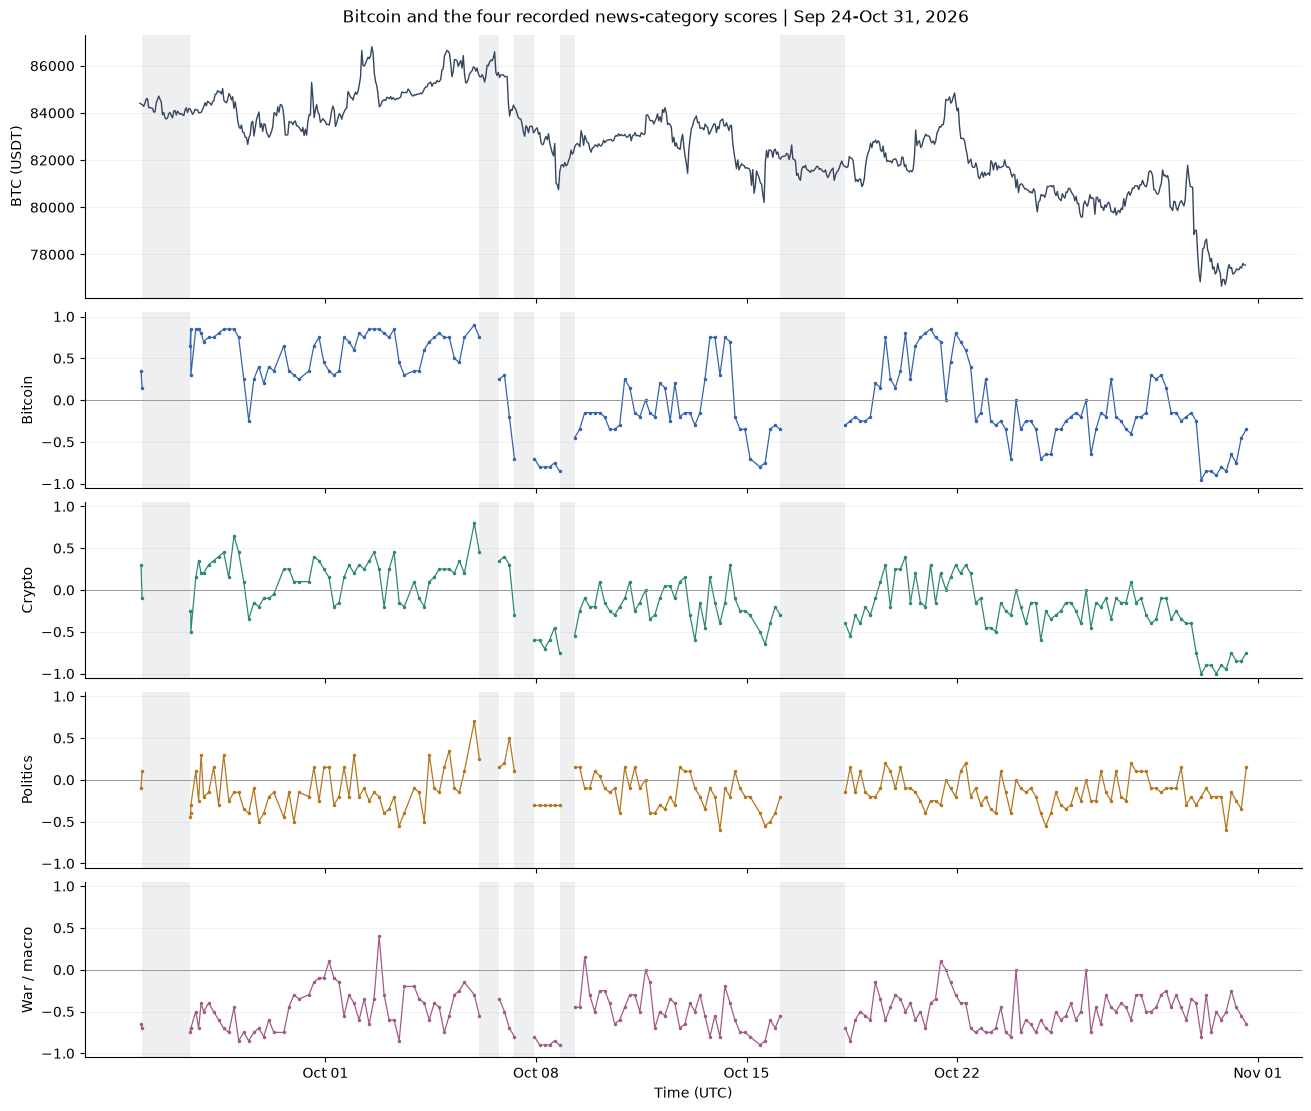

In [5]:
signals["previous_timestamp"]=signals.timestamp.shift()
signals["gap_hours"]=signals.timestamp.diff().dt.total_seconds()/3600
gaps=signals.loc[signals.gap_hours.gt(12)]
fig,axes=plt.subplots(5,1,figsize=(13,11),sharex=True,layout="constrained",
                      gridspec_kw={"height_ratios":[1.5,1,1,1,1]})
axes[0].plot(market.open_time,market.open,color="#34465e",lw=1)
axes[0].set_ylabel("BTC (USDT)")
for ax,(column,label),color in zip(axes[1:],CATEGORIES.items(),COLORS):
    for _,group in signals.groupby(signals.gap_hours.gt(12).cumsum()):
        ax.plot(group.timestamp,group[column],".-",color=color,lw=.9,ms=3)
    ax.axhline(0,color="#999999",lw=.7)
    ax.set_ylabel(label)
    ax.set_ylim(-1.05,1.05)
for ax in axes:
    for gap in gaps.itertuples():
        ax.axvspan(gap.previous_timestamp,gap.timestamp,color="#8791a1",alpha=.14,lw=0)
    ax.grid(axis="y",alpha=.16)
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5,maxticks=8))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
axes[-1].set_xlabel("Time (UTC)")
fig.suptitle("Bitcoin and the four recorded news-category scores | Sep 24-Oct 31, 2026")
save_chart(fig,"categories_and_btc_price")


## Interpretation and approval boundary

The following summary reports the measured correlations without choosing weights. A category with the largest coefficient in these data is not automatically the best trading input. The categories may share information, and a relationship can depend on this short market period. Testing sixteen category/horizon pairs also gives more opportunities to find a large value by chance.


In [6]:
summary_rows=[]
for column,label in CATEGORIES.items():
    part=correlations.loc[correlations.score_column.eq(column)]
    longest=part.loc[part.horizon_hours.eq(24)].iloc[0]
    summary_rows.append({"category":label,"24h_pearson":longest.pearson,"24h_spearman":longest.spearman,
                         "minimum_pearson_across_horizons":part.pearson.min(),
                         "maximum_pearson_across_horizons":part.pearson.max()})
summary_table=pd.DataFrame(summary_rows)
display(summary_table.round(4))
summary_table.to_csv(OUT/"category_readout.csv",index=False)
checks=pd.DataFrame([
    {"check":"Only original 192 matching observations included","passed":True},
    {"check":"Input hashes verified","passed":True},
    {"check":"Prior P/news/TA correlations reproduced at all horizons","passed":True},
    {"check":"Independent endpoint/Pearson checks for all 16 combinations","passed":True},
    {"check":"Missing final horizons excluded; expected counts verified","passed":True},
])
display(checks)
checks.to_csv(OUT/"category_study_checks.csv",index=False)
report={"scope":"Approved descriptive category correlations only", "observations":192,
        "newer_observations_excluded":40,"horizons_hours":HORIZONS,
        "input_sha256":EXPECTED,"correlations":correlations.to_dict("records"),
        "limitations":["Short repeatedly explored sample","Overlapping returns and dependent scores",
                       "No causal or significance claim","No portfolio returns or weight selection"],
        "next_step_requires_approval":"Specify candidate news-category weights and selection/evaluation rules"}
(OUT/"category_study_summary.json").write_text(json.dumps(report,indent=2),encoding="utf-8")


,category,24h_pearson,24h_spearman,minimum_pearson_across_horizons,maximum_pearson_across_horizons
0,Bitcoin,0.0099,0.0152,-0.0491,0.0484
1,Crypto,0.0048,-0.0058,-0.0683,0.0072
2,Politics,0.0193,0.0266,0.0193,0.0721
3,War / macro,-0.0096,0.0181,-0.0096,0.0190


,check,passed
0,Only original 192 matching observations included,True
1,Input hashes verified,True
2,Prior P/news/TA correlations reproduced at all...,True
3,Independent endpoint/Pearson checks for all 16...,True
4,Missing final horizons excluded; expected coun...,True


4352

## Findings

All sixteen category/horizon combinations have Pearson and Spearman correlations below 0.10 in absolute magnitude. The largest absolute Pearson coefficient is +0.072 for politics at 1 hour. The largest absolute Spearman coefficient is +0.092 for Bitcoin at 12 hours. Both are weak descriptive associations.

At 24 hours, Pearson correlations are Bitcoin +0.010, crypto +0.005, politics +0.019 and war/macro -0.010, using 185 usable observations each. There is no clear category winner from this comparison and no basis here to claim that changing the category weights improves trading. This does not rule out nonlinear or conditional effects, which have not been tested.

No new category weights, threshold grids, trading simulations or evaluation on the newer forty observations have been run. Further analyses require separate approval. The previous research and Azure audit notebooks are preserved.
